Analysis of State-Level Data:
Pearson Correlation Coefficient (r): -0.1810
Coefficient of Determination (R-squared): 0.0327


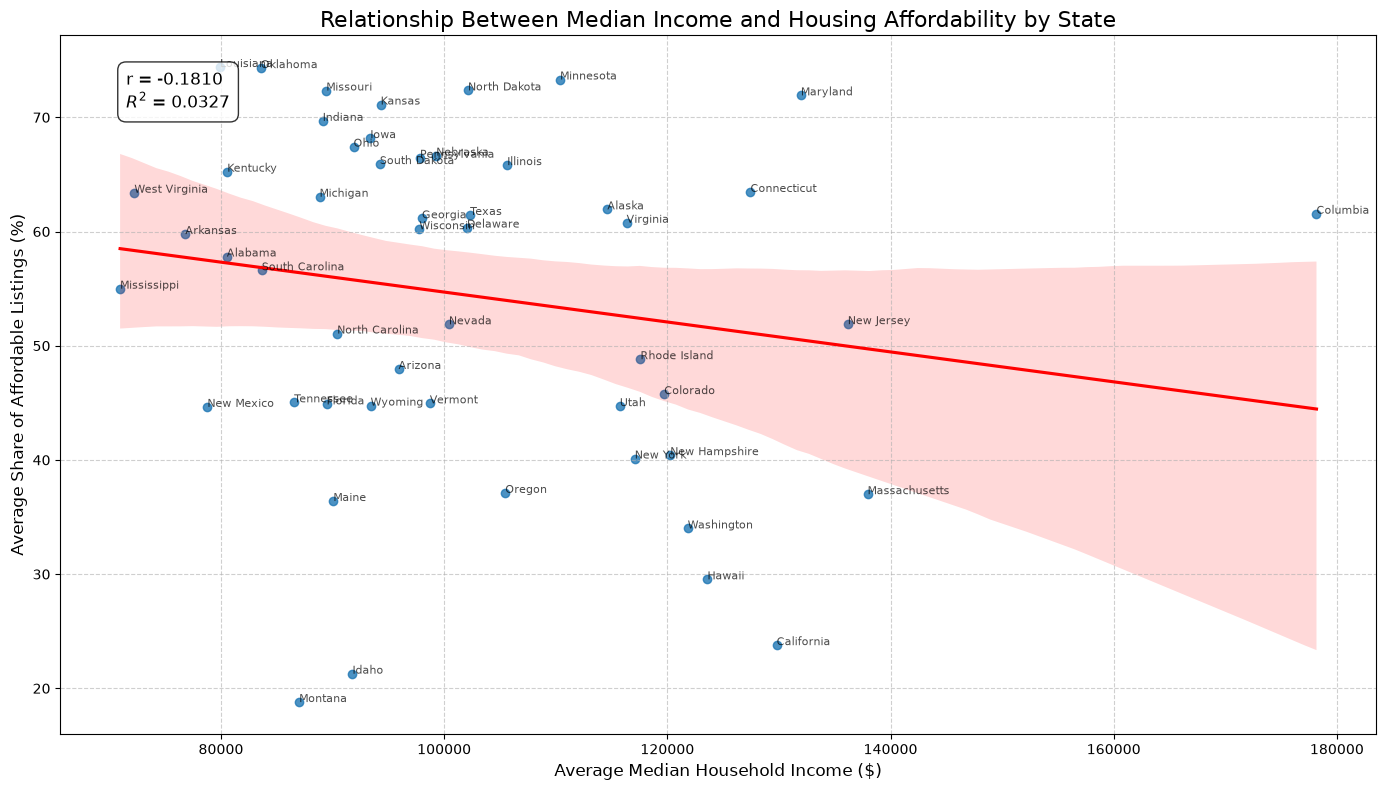

In [2]:
#Calculating house affordability based on a state's median household income


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Team Project\HomeownerDatasetForModeling_FinalCopy.csv"
df = pd.read_csv(path)

#  Aggregate the data by state ('REGION NAME') to get a single representative value per state.
#  calculate the mean of the relevant columns for each state across the entire time period.
state_agg = df.groupby('REGION NAME').agg({
    'MEDIAN HOUSEHOLD INCOME ($)': 'mean',
    'AFFORDABLE LISTING SHARE (%)': 'mean'
}).reset_index()

# 3. Define the variables for the scatter plot
x_var = 'MEDIAN HOUSEHOLD INCOME ($)'
y_var = 'AFFORDABLE LISTING SHARE (%)'
x = state_agg[x_var]
y = state_agg[y_var]

# 4. Calculate the Pearson correlation coefficient (r) and R-squared value
r, _ = stats.pearsonr(x, y)
r_squared = r**2

print(f"Analysis of State-Level Data:")
print(f"Pearson Correlation Coefficient (r): {r:.4f}")
print(f"Coefficient of Determination (R-squared): {r_squared:.4f}")

# 5. Create a scatterplot to visualize the relationship
plt.figure(figsize=(14, 8))
sns.regplot(x=x, y=y, line_kws={"color":"red"})

# Add labels for each point on the plot to identify the states
for i, row in state_agg.iterrows():
    plt.text(row[x_var], row[y_var], row['REGION NAME'], fontsize=8, alpha=0.7)

# Format the plot
plt.title('Relationship Between Median Income and Housing Affordability by State', fontsize=16)
plt.xlabel('Average Median Household Income ($)', fontsize=12)
plt.ylabel('Average Share of Affordable Listings (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# Add the correlation values as an annotation
plt.text(0.05, 0.95, f'r = {r:.4f}\n$R^2$ = {r_squared:.4f}',
         transform=plt.gca().transAxes,
         fontsize=12,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.5', fc='white', alpha=0.8))

plt.tight_layout()
plt.show()


Analyzing data for the most recent period: June 2026


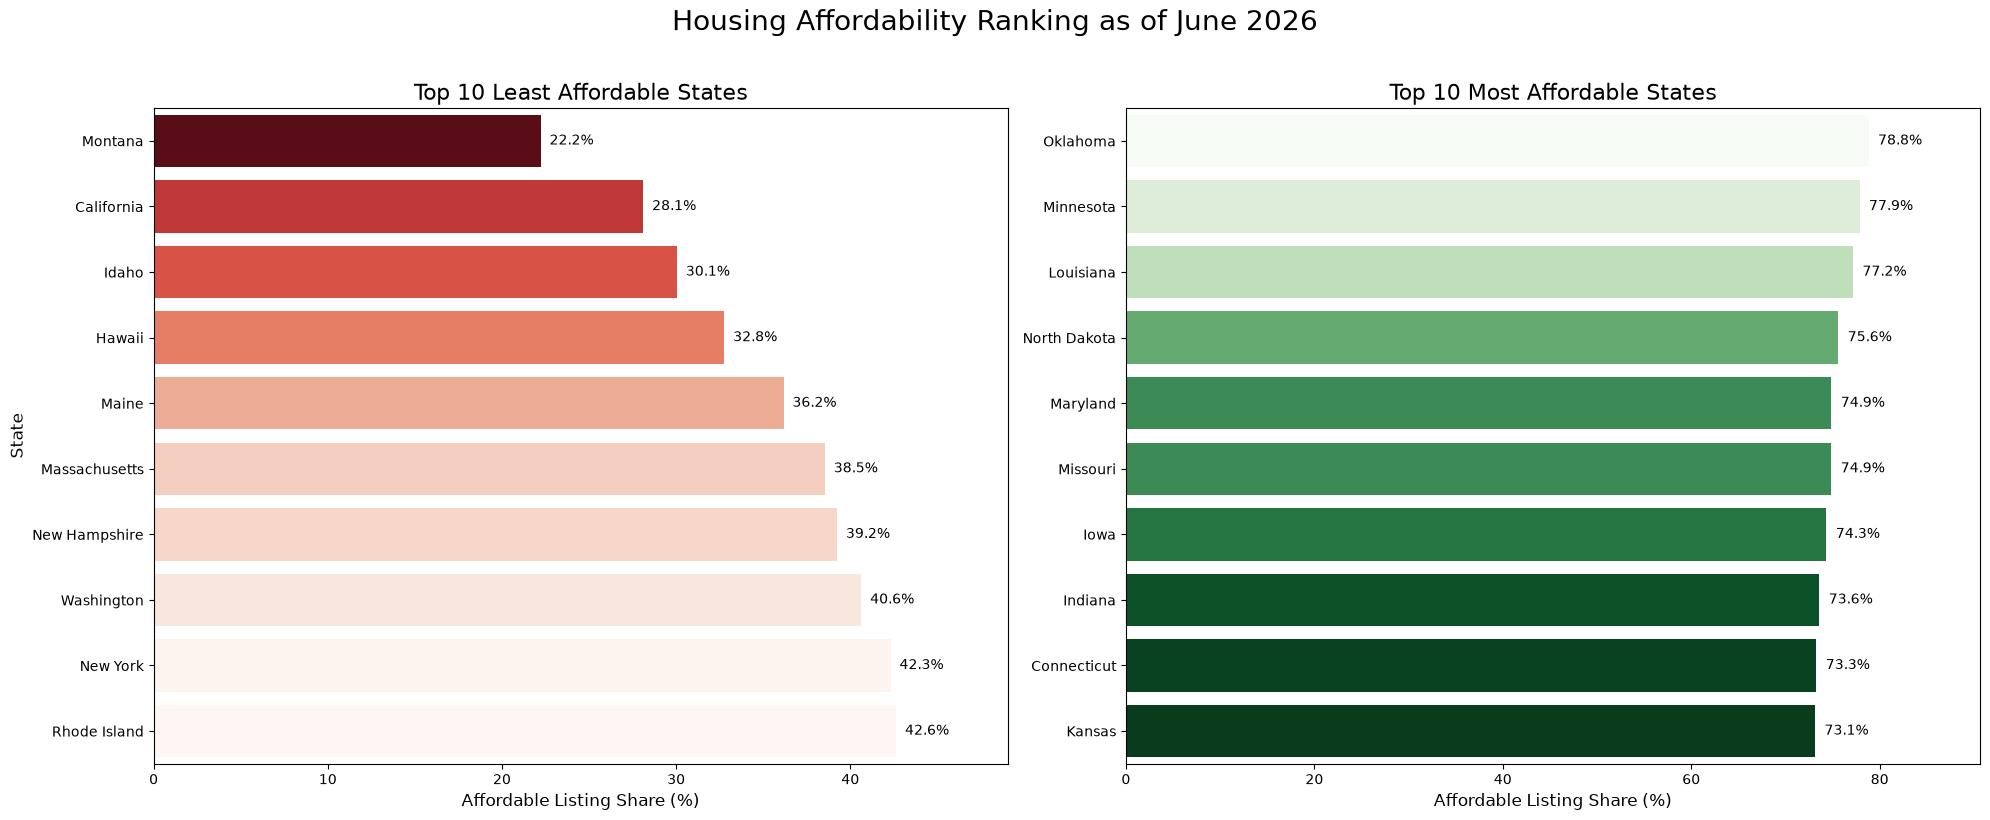

In [3]:
#Analysis of Affordability Rankings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Team Project\HomeownerDatasetForModeling_FinalCopy.csv"
df_filtered = pd.read_csv(path)

# 2. Convert 'PERIOD BEGIN' to datetime and find the most recent date
df_filtered['PERIOD BEGIN'] = pd.to_datetime(df_filtered['PERIOD BEGIN'])
most_recent_date = df_filtered['PERIOD BEGIN'].max()

print(f"Analyzing data for the most recent period: {most_recent_date.strftime('%B %Y')}")

# 3. Filter the DataFrame to include only data from the most recent period
recent_data = df_filtered[df_filtered['PERIOD BEGIN'] == most_recent_date]

# 4. Group by state, calculate the mean affordable listing share, and sort the results
# The mean is used to get a single value per state 
state_affordability = recent_data.groupby('REGION NAME')['AFFORDABLE LISTING SHARE (%)'].mean().sort_values()

# 5. Identify the top 10 least and most affordable states
least_affordable = state_affordability.head(10)
most_affordable = state_affordability.tail(10).sort_values(ascending=False)

# 6. Create the plots
plt.figure(figsize=(20, 8))

# --- Plot for the 10 Least Affordable States ---
plt.subplot(1, 2, 1)
#ax1 = sns.barplot(x=least_affordable.values, y=least_affordable.index, palette='Reds_r')

ax1 = sns.barplot(x=least_affordable.values,
                 y=least_affordable.index,
                 hue=least_affordable.values , palette ='Reds_r', legend=False )


plt.title('Top 10 Least Affordable States', fontsize=16)
plt.xlabel('Affordable Listing Share (%)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.xlim(0, max(least_affordable.values) * 1.15) # Adjust x-axis limit for text

# Add annotations to the bars
for index, value in enumerate(least_affordable):
    ax1.text(value + 0.5, index, f'{value:.1f}%', color='black', ha='left', va='center')

# --- Plot for the 10 Most Affordable States ---
plt.subplot(1, 2, 2)
#ax2 = sns.barplot(x=most_affordable.values, y=most_affordable.index, palette='Greens_r')

ax2 = sns.barplot(x=most_affordable.values,
                 y=most_affordable.index,
                 hue=most_affordable.values , palette ='Greens_r', legend=False )

plt.title('Top 10 Most Affordable States', fontsize=16)
plt.xlabel('Affordable Listing Share (%)', fontsize=12)
plt.ylabel('') # Hide y-label as it's clear
plt.xlim(0, max(most_affordable.values) * 1.15) # Adjust x-axis limit for text

# Add annotations to the bars
for index, value in enumerate(most_affordable):
    ax2.text(value + 1, index, f'{value:.1f}%', color='black', ha='left', va='center')

plt.suptitle(f'Housing Affordability Ranking as of {most_recent_date.strftime("%B %Y")}', fontsize=20, y=1.02)
plt.tight_layout()
plt.show()



Average Years to Save for a Down Payment by Property Type:
PROPERTY TYPE
Starter Home     5.497633
Condo/Co-op      6.809584
Townhouse        7.663653
Single Family    8.417131
Name: YEARS TO SAVE DOWN PAYMENT, dtype: float64


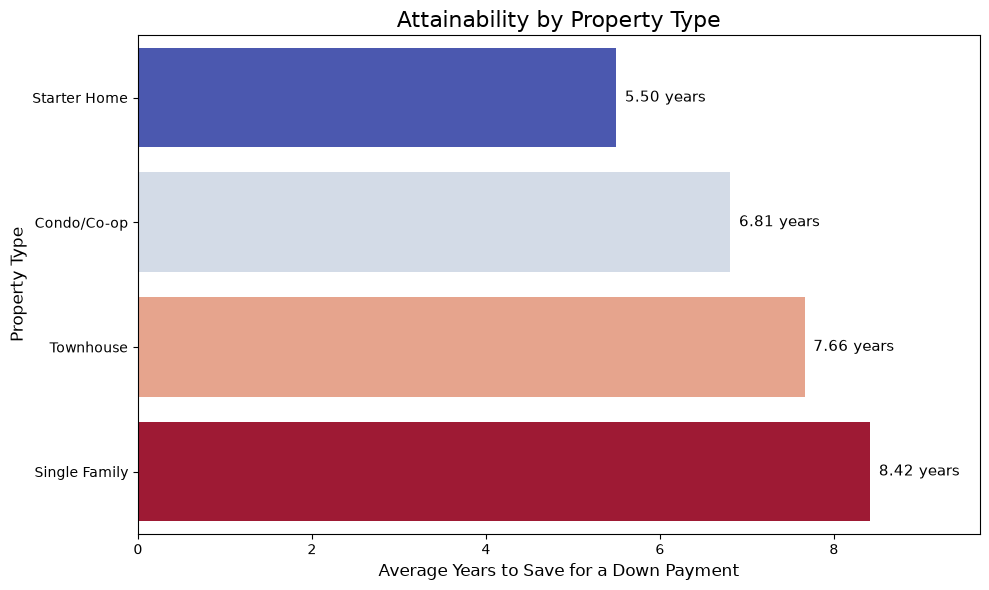

In [4]:
#calculate the average YEARS TO SAVE DOWN PAYMENT for each group. 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
path = r"C:\Users\malee\OneDrive\Desktop\Team Project\HomeownerDatasetForModeling_FinalCopy.csv"
df = pd.read_csv(path)


# 2. Group data by 'PROPERTY TYPE' and calculate the mean 'YEARS TO SAVE DOWN PAYMENT'
# This metric directly relates to how attainable a property is.
attainability_by_type = df_filtered.groupby('PROPERTY TYPE')['YEARS TO SAVE DOWN PAYMENT'].mean().sort_values(ascending=True)

print("Average Years to Save for a Down Payment by Property Type:")
print(attainability_by_type)

# 3. Create a horizontal bar chart for clear visualization
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=attainability_by_type.values, y=attainability_by_type.index,
            hue=attainability_by_type.values, palette='coolwarm', legend=False)

# 4. Add titles and labels for context and clarity
plt.title('Attainability by Property Type', fontsize=16)
plt.xlabel('Average Years to Save for a Down Payment', fontsize=12)
plt.ylabel('Property Type', fontsize=12)

# Annotate each bar with the precise value for better understanding
for index, value in enumerate(attainability_by_type):
    ax.text(value + 0.1, index, f'{value:.2f} years', color='black', ha='left', va='center', fontsize=11)

# Adjust the x-axis limit to ensure annotations fit
plt.xlim(0, max(attainability_by_type.values) * 1.15)

plt.tight_layout()
plt.show()

